# Coherent QPSK Optical-System Simulation at 10 GBaud (1550 nm)

This notebook implements an end-to-end numerical simulation of a traditional coherent optical system using QPSK at 10 GBaud and 1550 nm over standard single-mode fiber (SSMF).

Fiber propagation is modeled using the Split-Step Fourier Method (SSFM), based on `Fibra_Monomodo.m` (M. Segatto & A. Togneri, DEL/CT/UFES).

### Three Main Analyses
1. **Analysis 1:** BER vs. distance (100–1200 km in 100 km steps), with carrier and LO at the same phase (ideal case). Compare **no CDC** and **CDC** at launch powers of −10, 0, and +10 dBm.
2. **Analysis 2:** BER vs. independent phase noise at 100 km (independent lasers, \(\rho=0\)), with no DSP phase recovery.
3. **Analysis 3:** BER vs. linewidth at 100 km with highly correlated phase (self-homodyne/frequency-comb case), comparing \(\rho=0\), \(0.99\), and \(0.9999\).

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# Add the project root to the path to import src
sys.path.append(os.path.abspath(".."))

from src.dsp.transmitter import generate_qpsk_symbols, modulate_optical_signal
from src.dsp.fiber import fibra_monomodo, FiberParams
from src.dsp.noise_models import generate_correlated_phases, add_awgn_noise
from src.dsp.receiver import coherent_detection, cd_compensation, sample_to_symbols, demap_qpsk
from src.utils.metrics import calculate_ber, calculate_evm
from src.utils.filtros import aplicar_filtro

# Ensure artifact directories exist
os.makedirs("../artifacts/figures", exist_ok=True)
os.makedirs("../artifacts/reports", exist_ok=True)

print("DSP modules and utilities loaded successfully!")

DSP modules and utilities loaded successfully!


## 1. Global System Parameters

The symbol count and samples per symbol (SpS) are powers of two:
- \(N_{\text{sym}} = 16{,}384 = 2^{14}\)
- \(\text{SpS} = 8 = 2^3\)
- \(R_s = 10\text{ GBaud} \implies T_s = 100\text{ ps}\)

In [2]:
NUM_SYMBOLS = 2**14           # Power of two: 2^14
SPS = 2**4                   # Power of two: 2^3
SYMBOL_RATE = 10e9           # 10 GBaud
WAVELENGTH = 1550e-9         # 1550 nm
AMOSTRAGEM = SYMBOL_RATE*SPS # Sampling rate
FIBER_PARAMS = FiberParams()

print(f"Transmitter Configuration:")
print(f" - Number of Symbols: {NUM_SYMBOLS} (2^{int(np.log2(NUM_SYMBOLS))})")
print(f" - Samples per Symbol (SpS): {SPS} (2^{int(np.log2(SPS))})")
print(f" - Symbol Rate: {SYMBOL_RATE/1e9:.1f} GBaud")
print(f" - Wavelength: {WAVELENGTH*1e9:.1f} nm")
print(f" - Dispersion D: {FIBER_PARAMS.d_1550} ps/(nm*km)")

Transmitter Configuration:
 - Number of Symbols: 16384 (2^14)
 - Samples per Symbol (SpS): 16 (2^4)
 - Symbol Rate: 10.0 GBaud
 - Wavelength: 1550.0 nm
 - Dispersion D: 16.0 ps/(nm*km)


## 2. Analysis 1: BER vs. Distance (100–1200 km)

- The carrier and local oscillator have **exactly the same phase** (ideal case, \(\Delta\phi=0\)).
- Compare:
  1. **No CDC:** cumulative ISI due to fiber chromatic dispersion.
  2. **With CDC:** static frequency-domain equalization using \(H_{\text{CDC}}(\omega)=\exp(+jD\lambda^2L\omega^2/(4\pi c))\).
- Tested launch powers: **−10 dBm**, **0 dBm**, and **+10 dBm**.

In [3]:
distances = np.arange(100, 1300, 100) # 100 km a 1200 km
powers_dbm = [-10.0, 0.0, 10.0]
snr_ref_db = 16.0 # SNR aditiva constante
isPlot = True
contPlot = 1
numPlots = 1
results_a1 = {}

for p_dbm in powers_dbm:
    ber_no_cdc = []
    ber_with_cdc = []

    for dist in distances:
        symbols, bits = generate_qpsk_symbols(NUM_SYMBOLS, seed=42)
        u_tx, t, dt = modulate_optical_signal(symbols, sps=SPS, launch_power_dbm=p_dbm, symbol_rate=SYMBOL_RATE)
        
        steps = max(5, int(dist / 100 * 10))
        u_rx, _, _ = fibra_monomodo(t, u_tx, wavelength=WAVELENGTH, t0=100e-12, length_km=dist, regime=1, params=FIBER_PARAMS, num_steps=steps)
        u_rx_noisy = add_awgn_noise(u_rx, snr_db=snr_ref_db, seed=int(dist))
        
        # Beating with identical phase (ideal case)
        r_bb = coherent_detection(u_rx_noisy, phase_lo=np.zeros(len(t)))

        # Without CDC
        syms_no_cdc = sample_to_symbols(r_bb, sps=SPS)
        bits_no_cdc = demap_qpsk(syms_no_cdc)
        ber_no_cdc.append(calculate_ber(bits, bits_no_cdc))
        
        # With CDC
        r_cdc = cd_compensation(r_bb, dt=dt, length_km=dist, dispersion_d=FIBER_PARAMS.d_1550)
        syms_cdc = sample_to_symbols(r_cdc, sps=SPS)
        bits_cdc = demap_qpsk(syms_cdc)
        ber_with_cdc.append(calculate_ber(bits, bits_cdc))
        
    results_a1[p_dbm] = {"no_cdc": ber_no_cdc, "with_cdc": ber_with_cdc}



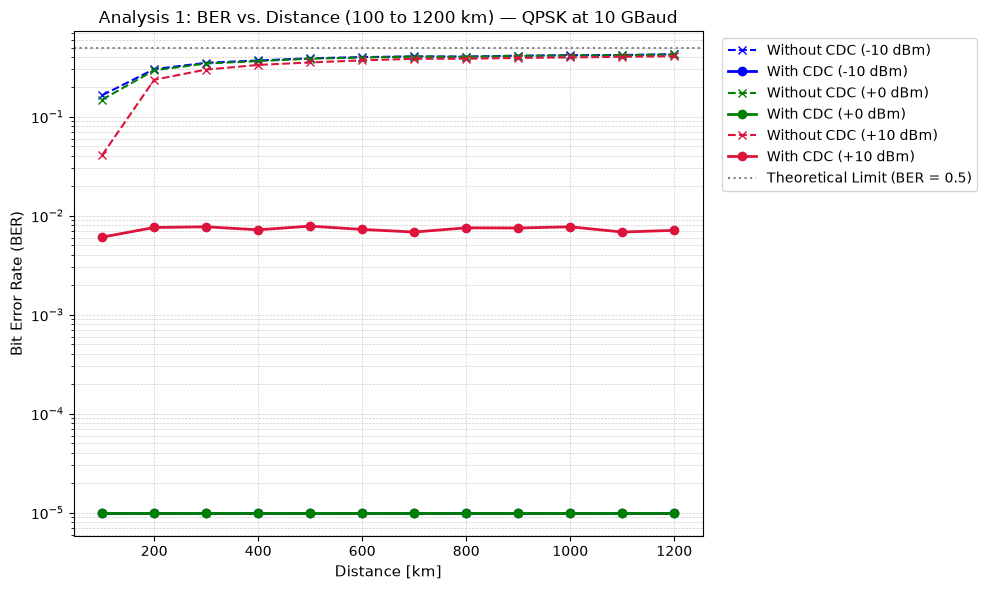

In [4]:
# Plot Analysis 1
plt.figure(figsize=(10, 6))
colors = {-10.0: "blue", 0.0: "green", 10.0: "crimson"}

for p_dbm, res in results_a1.items():
    c = colors[p_dbm]
    plt.semilogy(distances, np.maximum(res["no_cdc"], 1e-5), f"--x", color=c, label=f"Without CDC ({p_dbm:+.0f} dBm)")
    plt.semilogy(distances, np.maximum(res["with_cdc"], 1e-5), f"-o", color=c, linewidth=2, label=f"With CDC ({p_dbm:+.0f} dBm)")

plt.axhline(y=0.5, color="gray", linestyle=":", label="Theoretical Limit (BER = 0.5)")
plt.title("Analysis 1: BER vs. Distance (100 to 1200 km) — QPSK at 10 GBaud", fontsize=12)
plt.xlabel("Distance [km]", fontsize=11)
plt.ylabel("Bit Error Rate (BER)", fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig("../artifacts/figures/notebook_analise_1.png", dpi=300)
plt.show()

## 3. Analysis 2: BER vs. Independent Phase Noise at 100 km

- Fixed distance of 100 km with static dispersion compensation using CDC.
- **Independent** lasers (ρ = 0, conventional intradyne receiver).
- Laser phase noise follows a Wiener process, with linewidth \(\Delta\nu\) from 0 kHz to 10 MHz.
- No DSP phase-recovery algorithm is used, showing the direct effect of phase noise on demapping.

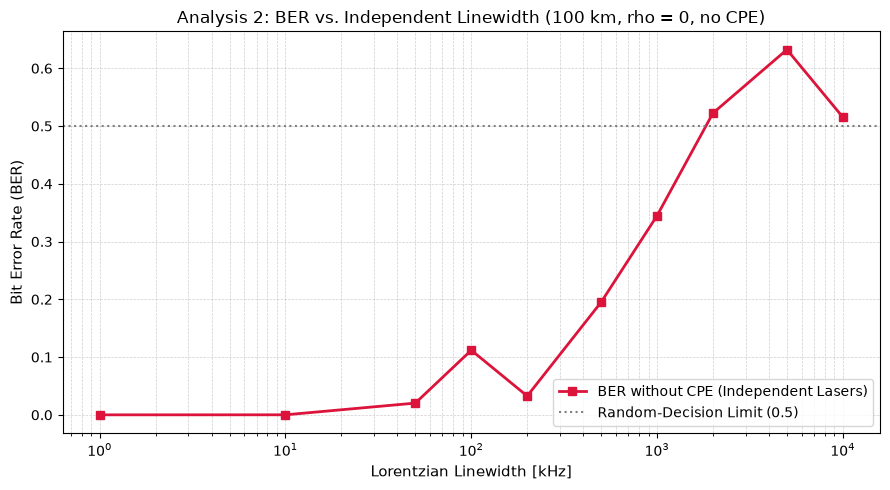

In [5]:
dist_fixed = 100.0
snr_ref_db = 20.0
linewidths_hz = np.array([0, 10e3, 50e3, 100e3, 200e3, 500e3, 1e6, 2e6, 5e6, 10e6])

symbols, bits = generate_qpsk_symbols(NUM_SYMBOLS, seed=42)
u_tx, t, dt = modulate_optical_signal(symbols, sps=SPS, launch_power_dbm=0.0, symbol_rate=SYMBOL_RATE)

# Propagation and CDC
u_rx_fiber, _, _ = fibra_monomodo(t, u_tx, wavelength=WAVELENGTH, t0=100e-12, length_km=dist_fixed, regime=1, params=FIBER_PARAMS, num_steps=10)
u_rx_cdc = cd_compensation(u_rx_fiber, dt=dt, length_km=dist_fixed, dispersion_d=FIBER_PARAMS.d_1550)
u_rx_cdc_noisy = add_awgn_noise(u_rx_cdc, snr_db=snr_ref_db, seed=100)

ber_a2 = []
for lw in linewidths_hz:
    phi_tx, phi_lo = generate_correlated_phases(len(t), dt=dt, linewidth_hz=lw, correlation_rho=0.0, seed=int(lw))
    u_rx_ph = u_rx_cdc_noisy * np.exp(1j * phi_tx)
    r_bb = coherent_detection(u_rx_ph, phase_lo=phi_lo)
    
    syms_rx = sample_to_symbols(r_bb, sps=SPS)
    bits_rx = demap_qpsk(syms_rx)
    ber_a2.append(calculate_ber(bits, bits_rx))

# Plot Analysis 2
plt.figure(figsize=(9, 5))
lw_khz = np.where(linewidths_hz == 0, 1.0, linewidths_hz / 1e3)
plt.semilogx(lw_khz, ber_a2, "-s", color="crimson", linewidth=2, markersize=6, label="BER without CPE (Independent Lasers)")
plt.axhline(y=0.5, color="gray", linestyle=":", label="Random-Decision Limit (0.5)")
plt.title("Analysis 2: BER vs. Independent Linewidth (100 km, rho = 0, no CPE)", fontsize=12)
plt.xlabel("Lorentzian Linewidth [kHz]", fontsize=11)
plt.ylabel("Bit Error Rate (BER)", fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../artifacts/figures/notebook_analise_2.png", dpi=300)
plt.show()

## 4. Analysis 3: BER vs. Linewidth with Highly Correlated Phase (100 km)

- Fixed distance of 100 km.
- Compare three correlation regimes:
  1. \(\rho=0.0\): independent lasers (conventional).
  2. \(\rho=0.99\): moderate-to-high correlation (99%).
  3. \(\rho=0.9999\): **high phase correlation** (99.99%), representative of optical frequency combs (OFC) and **self-homodyne (Coherent-Lite)** systems.
- No DSP phase recovery is used.

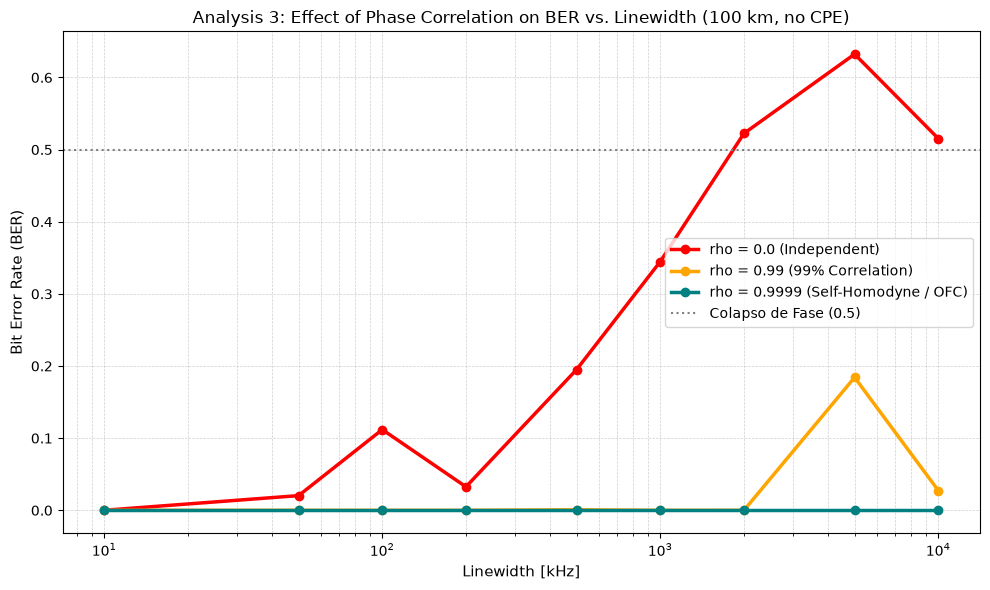

In [6]:
linewidths_hz_a3 = np.array([10e3, 50e3, 100e3, 200e3, 500e3, 1e6, 2e6, 5e6, 10e6])
rhos = [0.0, 0.99, 0.9999]
colors_a3 = {0.0: "red", 0.99: "orange", 0.9999: "teal"}
labels_a3 = {
    0.0: "rho = 0.0 (Independent)",
    0.99: "rho = 0.99 (99% Correlation)",
    0.9999: "rho = 0.9999 (Self-Homodyne / OFC)"
}

results_a3 = {}
for rho in rhos:
    ber_list = []
    for lw in linewidths_hz_a3:
        phi_tx, phi_lo = generate_correlated_phases(len(t), dt=dt, linewidth_hz=lw, correlation_rho=rho, seed=int(lw + rho*1e6))
        u_rx_ph = u_rx_cdc_noisy * np.exp(1j * phi_tx)
        r_bb = coherent_detection(u_rx_ph, phase_lo=phi_lo)
        
        syms_rx = sample_to_symbols(r_bb, sps=SPS)
        bits_rx = demap_qpsk(syms_rx)
        ber_list.append(calculate_ber(bits, bits_rx))
    results_a3[rho] = ber_list

# Plot Analysis 3
plt.figure(figsize=(10, 6))
lw_khz_a3 = linewidths_hz_a3 / 1e3

for rho in rhos:
    plt.semilogx(lw_khz_a3, results_a3[rho], "-o", color=colors_a3[rho], linewidth=2.5, markersize=6, label=labels_a3[rho])

plt.axhline(y=0.5, color="gray", linestyle=":", label="Colapso de Fase (0.5)")
plt.title("Analysis 3: Effect of Phase Correlation on BER vs. Linewidth (100 km, no CPE)", fontsize=12)
plt.xlabel("Linewidth [kHz]", fontsize=11)
plt.ylabel("Bit Error Rate (BER)", fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(loc="center right", fontsize=10)
plt.tight_layout()
plt.savefig("../artifacts/figures/notebook_analise_3.png", dpi=300)
plt.show()

## 5. QPSK Constellation Visualization

Compare received constellations for three cases:
1. **Ideal:** no phase noise, CDC enabled.
2. **Independent (ρ = 0):** 1 MHz linewidth; the constellation rotates and becomes disordered.
3. **Self-homodyne (ρ = 0.9999):** 1 MHz linewidth; common-mode phase cancellation preserves the constellation.

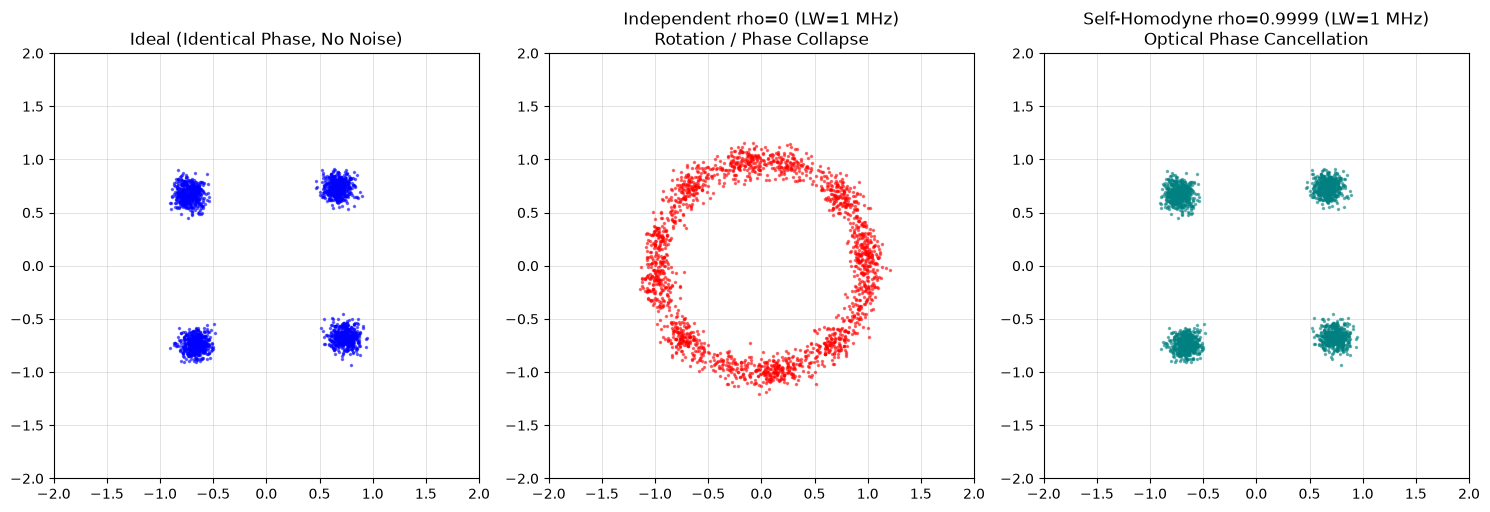

In [7]:
lw_test = 1e6 # 1 MHz

# 1. Ideal
r_ideal = coherent_detection(u_rx_cdc_noisy, phase_lo=np.zeros(len(t)))
s_ideal = sample_to_symbols(r_ideal, sps=SPS)[:2000]

# 2. Independent lasers (rho = 0)
p_tx_ind, p_lo_ind = generate_correlated_phases(len(t), dt, lw_test, correlation_rho=0.0, seed=123)
r_ind = coherent_detection(u_rx_cdc_noisy * np.exp(1j*p_tx_ind), phase_lo=p_lo_ind)
s_ind = sample_to_symbols(r_ind, sps=SPS)[:2000]

# 3. Correlacionado (rho = 0.9999)
p_tx_corr, p_lo_corr = generate_correlated_phases(len(t), dt, lw_test, correlation_rho=0.9999, seed=123)
r_corr = coherent_detection(u_rx_cdc_noisy * np.exp(1j*p_tx_corr), phase_lo=p_lo_corr)
s_corr = sample_to_symbols(r_corr, sps=SPS)[:2000]

# Plot the three constellations side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
s_ideal = s_ideal/np.sqrt(np.mean(np.abs(s_ideal)**2))
axes[0].plot(np.real(s_ideal), np.imag(s_ideal), '.', color='blue', alpha=0.5, markersize=3)
axes[0].set_title("Ideal (Identical Phase, No Noise)")
axes[0].set_xlim([-2, 2]); axes[0].set_ylim([-2, 2]); axes[0].grid(True); axes[0].set_aspect('equal')

s_ind = s_ind/np.sqrt(np.mean(np.abs(s_ind)**2))
axes[1].plot(np.real(s_ind), np.imag(s_ind), '.', color='red', alpha=0.5, markersize=3)
axes[1].set_title("Independent rho=0 (LW=1 MHz)\nRotation / Phase Collapse")
axes[1].set_xlim([-2, 2]); axes[1].set_ylim([-2, 2]); axes[1].grid(True); axes[1].set_aspect('equal')

s_corr = s_corr/np.sqrt(np.mean(np.abs(s_corr)**2))
axes[2].plot(np.real(s_corr), np.imag(s_corr), '.', color='teal', alpha=0.5, markersize=3)
axes[2].set_title("Self-Homodyne rho=0.9999 (LW=1 MHz)\nOptical Phase Cancellation")
axes[2].set_xlim([-2, 2]); axes[2].set_ylim([-2, 2]); axes[2].grid(True); axes[2].set_aspect('equal')

plt.tight_layout()
plt.savefig("../artifacts/figures/comparacao_constelacoes.png", dpi=300)
plt.show()